# Synthetic Thai text images for billboard text reading

Generator for a synthetic dataset of Thai text on textured backgrounds, with bounding-box annotations and data augmentation. It was written for a computer vision term project on reading text from billboards. See the README in this folder for the purpose, the method, and what is and is not included.


In [ ]:
!pip install -q Pillow numpy opencv-python datasets pythainlp


In [ ]:
!mkdir -p fonts backgrounds thai_text_dataset


In [ ]:
# Download the Thai fonts (Google Fonts, OFL licence)
!wget -q -P fonts https://github.com/google/fonts/raw/main/ofl/prompt/Prompt-Regular.ttf
!wget -q -P fonts https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf
!wget -q -P fonts https://github.com/google/fonts/raw/main/ofl/kanit/Kanit-Regular.ttf
!ls -la fonts/

total 440
drwxr-xr-x 2 root root   4096 Apr 18 15:22 .
drwxr-xr-x 1 root root   4096 Apr 18 15:22 ..
-rw-r--r-- 1 root root 173148 Apr 18 15:22 Kanit-Regular.ttf
-rw-r--r-- 1 root root 168932 Apr 18 15:22 Prompt-Regular.ttf
-rw-r--r-- 1 root root  90220 Apr 18 15:22 Sarabun-Regular.ttf


Put your own background images (`.jpg`, `.jpeg` or `.png`) in `backgrounds/`. They are not included in this repository.


In [ ]:
import json
import os
import random
import re
from copy import deepcopy
from datetime import datetime

import cv2
import numpy as np
from datasets import load_dataset
from PIL import Image, ImageDraw, ImageFont
from pythainlp.tokenize import word_tokenize


class ThaiTextDatasetGenerator:
    """Synthetic Thai text images with bounding-box annotations and augmentation."""

    def __init__(self, fonts_dir, backgrounds_dir, output_dir):
        self.output_dir = output_dir
        self.images_dir = os.path.join(output_dir, "images")
        self.annotations_dir = os.path.join(output_dir, "annotations")
        os.makedirs(self.images_dir, exist_ok=True)
        os.makedirs(self.annotations_dir, exist_ok=True)

        self.fonts = self._list_files(fonts_dir, (".ttf", ".otf"))
        self.backgrounds = self._list_files(backgrounds_dir, (".jpg", ".jpeg", ".png"))
        self.wiki = self._load_thai_wiki()

    @staticmethod
    def _list_files(directory, extensions):
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(extensions)]

    @staticmethod
    def _load_thai_wiki():
        """Load the first 5% of the Thai Wikipedia dataset from Hugging Face."""
        print("Loading Thai Wikipedia data...")
        dataset = load_dataset("pythainlp/thai-wiki-dataset-v3", split="train[:5%]")
        print(f"Loaded Wikipedia data: {len(dataset)} articles")
        return dataset

    def _random_wiki_word(self, min_len=5, max_len=20):
        """Pick one random word from a random article: Thai characters only, min_len to max_len long."""
        while True:
            text = random.choice(self.wiki).get("text", "")
            if not text:
                continue
            words = [
                w for w in word_tokenize(text, engine="newmm")
                if min_len <= len(w) <= max_len and re.fullmatch(r"[ก-๙]+", w)
            ]
            if words:
                return random.choice(words)

    @staticmethod
    def _text_size(draw, text, font):
        left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
        return right - left, bottom - top

    def _save_annotation(self, image_id, annotation):
        path = os.path.join(self.annotations_dir, f"{image_id}.json")
        with open(path, "w", encoding="utf-8") as f:
            json.dump(annotation, f, ensure_ascii=False, indent=2)

    def create_synthetic_image(self):
        """Render one Thai word on a random background; save the image and its JSON annotation."""
        text = self._random_wiki_word()
        font_path = random.choice(self.fonts)
        bg_path = random.choice(self.backgrounds)

        bg = Image.open(bg_path).convert("RGB").resize((800, 600))
        draw = ImageDraw.Draw(bg)

        font_size = random.randint(120, 150)
        font = ImageFont.truetype(font_path, font_size)
        text_color = tuple(random.randint(200, 255) for _ in range(3))  # bright, close to white

        # Shrink the font until the text fits in the image (never below size 10).
        text_width, text_height = self._text_size(draw, text, font)
        while text_width > bg.width - 40 or text_height > bg.height - 40:
            font_size -= 2
            if font_size < 10:
                break
            font = ImageFont.truetype(font_path, font_size)
            text_width, text_height = self._text_size(draw, text, font)

        # Centre the text.
        padding = 10
        x = (bg.width - text_width - 2 * padding) / 2
        y = (bg.height - text_height - 2 * padding) / 2
        draw.text((x, y), text, font=font, fill=text_color)

        image_id = f"thai_text_{datetime.now():%Y%m%d_%H%M%S}_{random.randint(1000, 9999)}"
        image_path = os.path.join(self.images_dir, image_id + ".jpg")
        bg.save(image_path)

        annotation = {
            "image_id": image_id,
            "file_path": image_path,
            "width": bg.width,
            "height": bg.height,
            "source": "synthetic",
            "annotations": [{
                "id": 1,
                # [x_min, y_min, x_max, y_max], padded around the text
                "bbox": [x - padding - 20, y - padding - 20,
                         x + text_width + padding + 20, y + text_height + padding + 50],
                "text": text,
                "language": "thai",
                "confidence": 1.0,
            }],
            "metadata": {
                "category": "wiki",
                "font": os.path.basename(font_path),
                "background": os.path.basename(bg_path),
            },
        }
        self._save_annotation(image_id, annotation)
        return image_path, annotation

    def apply_augmentation(self, image_path, annotation, num_augmentations=3):
        """Save augmented copies of an image: brightness, contrast, perspective, noise and blur."""
        image = cv2.imread(image_path)
        name, ext = os.path.splitext(os.path.basename(image_path))
        results = []

        for i in range(num_augmentations):
            aug_image = image.copy()
            aug_annotation = deepcopy(annotation)
            aug_bbox = list(annotation["annotations"][0]["bbox"])

            brightness = random.uniform(0.7, 1)
            aug_image = cv2.convertScaleAbs(aug_image, alpha=brightness, beta=0)
            contrast = random.uniform(0.7, 1.3)
            aug_image = cv2.convertScaleAbs(aug_image, alpha=contrast, beta=0)

            # Perspective transform: move each corner of the text box by up to 10% of its size.
            perspective = random.random() < 0.7
            if perspective:
                x_min, y_min, x_max, y_max = aug_bbox
                shift_x = (x_max - x_min) * 0.1
                shift_y = (y_max - y_min) * 0.1
                src = np.float32([[x_min, y_min], [x_max, y_min], [x_max, y_max], [x_min, y_max]])
                dst = np.float32([[cx + random.uniform(-shift_x, shift_x),
                                   cy + random.uniform(-shift_y, shift_y)] for cx, cy in src])
                matrix = cv2.getPerspectiveTransform(src, dst)
                height, width = aug_image.shape[:2]
                aug_image = cv2.warpPerspective(aug_image, matrix, (width, height))

                # Move the bounding box with the same transform.
                moved = cv2.perspectiveTransform(src.reshape(-1, 1, 2), matrix)
                xs, ys = moved[:, 0, 0], moved[:, 0, 1]
                new_x_min, new_y_min = max(0, int(xs.min())), max(0, int(ys.min()))
                new_x_max, new_y_max = min(width, int(xs.max())), min(height, int(ys.max()))
                if new_x_max > new_x_min and new_y_max > new_y_min:
                    aug_bbox = [new_x_min, new_y_min, new_x_max, new_y_max]

            noise = random.random() < 0.3
            if noise:
                aug_image = cv2.add(aug_image, np.random.normal(0, 15, aug_image.shape).astype(np.uint8))

            blur = random.random() < 0.3
            if blur:
                size = random.choice([3, 5])
                aug_image = cv2.GaussianBlur(aug_image, (size, size), 0)

            aug_id = f"{name}_aug_{i}"
            aug_path = os.path.join(self.images_dir, aug_id + ext)
            cv2.imwrite(aug_path, aug_image)

            aug_annotation["image_id"] = aug_id
            aug_annotation["file_path"] = aug_path
            aug_annotation["source"] = "synthetic_augmented"
            aug_annotation["annotations"][0]["bbox"] = aug_bbox
            aug_annotation["metadata"]["augmentation"] = {
                "brightness": brightness,
                "contrast": contrast,
                "perspective": perspective,
                "noise": noise,
                "blur": blur,
            }
            self._save_annotation(aug_id, aug_annotation)
            results.append((aug_path, aug_annotation))

        return results

    def generate_dataset(self, num_images=100, augmentations_per_image=3):
        """Create num_images base images, each followed by its augmented copies, and write a summary file."""
        print(f"Generating {num_images} base images with {augmentations_per_image} augmented copies each")
        print(f"Fonts found: {len(self.fonts)}, backgrounds found: {len(self.backgrounds)}")

        all_images = []
        for i in range(num_images):
            if (i + 1) % 10 == 0:
                print(f"Generated {i + 1}/{num_images} images")
            image_path, annotation = self.create_synthetic_image()
            all_images.append((image_path, annotation))
            all_images.extend(self.apply_augmentation(image_path, annotation, augmentations_per_image))

        total_annotations = sum(len(a["annotations"]) for _, a in all_images)
        print("Dataset generation finished")
        print(f"Total images: {len(all_images)}")
        print(f"Total annotations: {total_annotations}")
        print(f"Images: {self.images_dir}")
        print(f"Annotations: {self.annotations_dir}")

        summary = {
            "total_images": len(all_images),
            "total_annotations": total_annotations,
            "base_images": num_images,
            "augmentations_per_image": augmentations_per_image,
            "date_generated": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        }
        with open(os.path.join(self.output_dir, "dataset_summary.json"), "w", encoding="utf-8") as f:
            json.dump(summary, f, ensure_ascii=False, indent=2)
        return summary

    def split_dataset(self, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
        """Shuffle the annotation files and write train.txt, val.txt and test.txt lists."""
        if abs(train_ratio + val_ratio + test_ratio - 1.0) > 1e-10:
            raise ValueError("The ratios must sum to 1.0")

        files = [f for f in os.listdir(self.annotations_dir) if f.endswith(".json")]
        random.shuffle(files)
        n_train = int(len(files) * train_ratio)
        n_val = int(len(files) * val_ratio)
        splits = {
            "train": files[:n_train],
            "val": files[n_train:n_train + n_val],
            "test": files[n_train + n_val:],
        }

        splits_dir = os.path.join(self.output_dir, "splits")
        os.makedirs(splits_dir, exist_ok=True)
        for split, names in splits.items():
            with open(os.path.join(splits_dir, f"{split}.txt"), "w", encoding="utf-8") as f:
                f.writelines(f"{n}\n" for n in names)

        summary = {
            "total_files": len(files),
            "train_files": len(splits["train"]),
            "val_files": len(splits["val"]),
            "test_files": len(splits["test"]),
            "train_ratio": train_ratio,
            "val_ratio": val_ratio,
            "test_ratio": test_ratio,
        }
        with open(os.path.join(splits_dir, "split_summary.json"), "w", encoding="utf-8") as f:
            json.dump(summary, f, ensure_ascii=False, indent=2)

        print("Split finished:")
        for split, label, ratio in (("train", "Training", train_ratio),
                                    ("val", "Validation", val_ratio),
                                    ("test", "Testing", test_ratio)):
            print(f"  {label}: {len(splits[split])} images ({ratio * 100:.1f}%)")
        return summary


In [ ]:
# Parameters
fonts_dir = './fonts'
backgrounds_dir = './backgrounds'
output_dir = './thai_text_dataset'
num_images = 2500  # reduced so that it runs faster on Colab
augmentations_per_image = 3

generator = ThaiTextDatasetGenerator(fonts_dir, backgrounds_dir, output_dir)
summary = generator.generate_dataset(num_images=num_images, augmentations_per_image=augmentations_per_image)
split_summary = generator.split_dataset(train_ratio=0.7, val_ratio=0.15, test_ratio=0.15)


Loading Thai Wikipedia data...
Loaded Wikipedia data: 9827 articles
Generating 2500 base images with 3 augmented copies each
Fonts found: 3, backgrounds found: 20
Generated 500/2500 images
Generated 1000/2500 images
Generated 1500/2500 images
Generated 2000/2500 images
Generated 2500/2500 images
Dataset generation finished
Total images: 10000
Total annotations: 10000
Images: ./thai_text_dataset/images
Annotations: ./thai_text_dataset/annotations
Split finished:
  Training: 7000 images (70.0%)
  Validation: 1500 images (15.0%)
  Testing: 1500 images (15.0%)


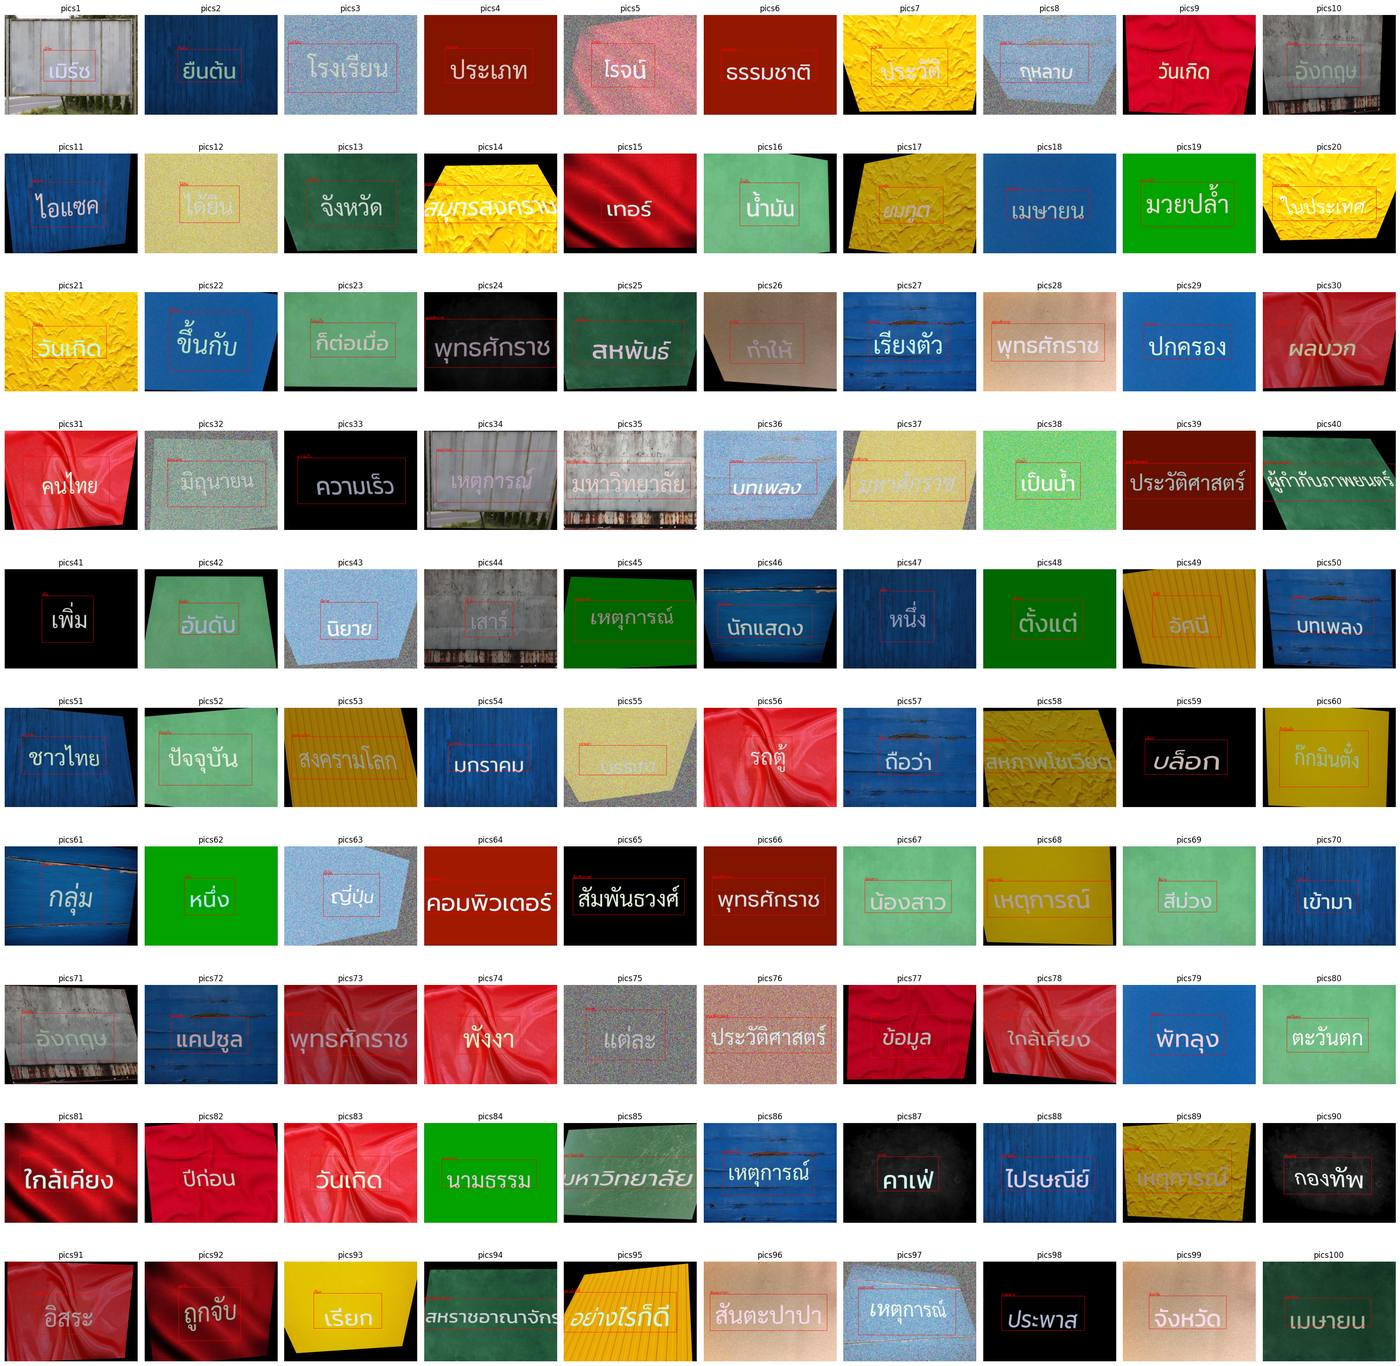

In [ ]:
# Show random samples with their annotations
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

images_dir = './thai_text_dataset/images'
annotations_dir = './thai_text_dataset/annotations'

# a font that can draw Thai (change the path if needed)
font_path = './fonts/Sarabun-Regular.ttf'
thai_font_pil = ImageFont.truetype(font_path, size=24)
thai_font_matplotlib = font_manager.FontProperties(fname=font_path)
plt.rcParams['font.family'] = thai_font_matplotlib.get_name()

image_files = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
sample_images = random.sample(image_files, min(100, len(image_files)))

plt.figure(figsize=(30, 30))
for i, img_file in enumerate(sample_images):
    img = Image.open(os.path.join(images_dir, img_file)).convert("RGB")
    with open(os.path.join(annotations_dir, os.path.splitext(img_file)[0] + '.json'), 'r', encoding='utf-8') as f:
        ann = json.load(f)

    draw = ImageDraw.Draw(img)
    for a in ann.get('annotations', []):
        x1, y1, x2, y2 = a['bbox']
        draw.rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=2)
        draw.text((x1, max(y1 - 25, 0)), a['text'], fill=(255, 0, 0), font=thai_font_pil)

    plt.subplot(10, 10, i + 1)
    plt.imshow(np.array(img))
    plt.title(f"pics{i+1}", fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# zip the dataset
!zip -q -r thai_text_dataset_2500x4.zip thai_text_dataset


In [ ]:
from google.colab import files
files.download('thai_text_dataset_2500x4.zip')
